# Lab 05: The Dark Companion, Two Years Later

**ASTR 457, Fall 2026, posted Sat Oct 3, due Fri Oct 9 by Noon (extended) (fork → PR, as always)**

*Why this lab: every orbit in the literature, from Gaia's black-hole binaries to the planets David Charbonneau talked about on Tuesday, is a posterior distribution over six or seven parameters that nobody can write down in closed form. Sampling it, knowing when the sampler has actually converged, and turning the samples into a number with an honest error bar is the core professional skill of modern astrophysics, and the place where confident, fluent, wrong analyses are most common.*

On Day 1 you watched a star's radial velocity drift over ten nights and inferred an unseen companion from
the slope alone. This is that programme, two and a half years on. Every one of you has your own star:
`data/<your netid>.csv`, with columns `t_days` (time of each spectrum, from the first epoch), `rv_kms`
(the measured radial velocity) and `sigma_rv_kms` (the pipeline's per-epoch uncertainty). The star was
observed in three observing seasons over about 900 days, 28 to 44 epochs in all. It is a **single-lined
spectroscopic binary**: you see one star's lines, the companion contributes no light, and the visible star
follows a Keplerian orbit,

$$v_r(t) = \gamma + K\left[\cos\big(\nu(t) + \omega\big) + e\cos\omega\right],$$

with period $P$, semi-amplitude $K$, eccentricity $e$, argument of periastron $\omega$, a time of periastron
$T_p$, systemic velocity $\gamma$, and $\nu(t)$ the true anomaly (the angle around the orbit, which you get
from Kepler's equation; a function is provided). What you are really after is the **mass function**

$$f(M) = \frac{P K^3 (1 - e^2)^{3/2}}{2\pi G} = \frac{M_2^3 \sin^3 i}{(M_1 + M_2)^2},$$

a lower limit on the companion's mass, in solar masses. If it comes out above about $3\,M_\odot$ for a
Sun-like primary, you have a black hole candidate, the way Gaia BH1 was found (El-Badry et al. 2023, the Sep 8
colloquium). In the units of your file, $f(M) = 1.0361\times10^{-7}\,(1-e^2)^{3/2} K^3 P$ with $K$ in km/s
and $P$ in days.

I know your true $P$, $K$, $e$ and $f(M)$. You don't, your classmates' stars are different, and so is the
sampling. **One more thing I know and you don't: the quoted `sigma_rv_kms` is not the whole error.** Real
radial velocities carry an extra scatter, called jitter, from the star's own surface and from template
mismatch, and it is not in the pipeline number.

**How this is graded.** As always, on whether your answers are *right* and your uncertainties are *honest*:
your reported $P$, $K$, $e$ and $f(M)$ are compared to your truth in units of your own reported uncertainty.
Anti-sandbagging cap: your $\sigma_K$ may not exceed $3\times$ a reference posterior width I compute for your
dataset. Padded error bars lose points like overconfident ones.

**AI policy reminder.** Use whatever tools you like, including AI assistants, and document it in Part 4. You
may be selected to defend this lab orally; the defense is easy if you did the work.

Weights: Part 1 15%, Part 2 40%, Part 3 35%, Part 4 10%.


In [39]:
import os

print(os.getcwd())
print(os.listdir())

/Users/c2027/ASTR457_2026_Fall/submissions/cmewing2
['lab01.ipynb', 'lab03.ipynb', 'cmewing2-2.csv', 'lab05.ipynb', 'Notes_for_Colloquium.pdf', 'lab02.ipynb', 'cmewing3.csv', 'cmewing2.csv', 'lab04.ipynb', 'lab05-Copy1.ipynb', 'inclass_day10_dwarf_agn.csv', '.ipynb_checkpoints', 'review_test_sep29.ipynb', 'ast.jpg']


In [91]:
!pip install emcee
!pip install corner
import numpy as np
import matplotlib.pyplot as plt
import emcee
import corner
from scipy.optimize import minimize
from astropy.timeseries import LombScargle


NETID = 'cmewing2'   # <-- set this
d = np.genfromtxt('cmewing2.csv', delimiter=',', names=True)
t, rv, sig = d['t_days'], d['rv_kms'], d['sigma_rv_kms']
print(f"{t.size} epochs over {t.max() - t.min():.0f} days; median quoted error {np.median(sig):.2f} km/s")
rv_real = rv.copy()
def kepler_rv(t, P, K, e, omega, Tp, gamma):
    """Radial velocity of the visible star in a Keplerian orbit.
    P period [d], K semi-amplitude [km/s], e eccentricity, omega argument of periastron [rad],
    Tp a time of periastron [d], gamma systemic velocity [km/s]. Solves Kepler's equation by Newton iteration."""
    M = 2. * np.pi * ((t - Tp) / P % 1.0)            # mean anomaly
    E = M.copy()                                     # eccentric anomaly
    for _ in range(30):
        E = E - (E - e * np.sin(E) - M) / (1. - e * np.cos(E))
    nu = 2. * np.arctan2(np.sqrt(1. + e) * np.sin(E / 2.), np.sqrt(1. - e) * np.cos(E / 2.))   # true anomaly
    return gamma + K * (np.cos(nu + omega) + e * np.cos(omega))

def mass_function(P, K, e):
    """f(M) in solar masses, for P in days and K in km/s."""
    return 1.0361e-7 * (1. - e**2)**1.5 * K**3 * P

42 epochs over 892 days; median quoted error 2.04 km/s


## Part 1: Look first, then find the period (15%)

Plot the radial velocities against time with their error bars. Then find candidate orbital periods with a
Lomb-Scargle periodogram of the velocities (`astropy.timeseries.LombScargle`, Day 7's periodogram, formally
taught on Oct 20/22; for now it is a tool that ranks periods). Plot the periodogram. Then, for the best two or
three candidate periods, phase-fold the data and look.

Answer, in a few sentences: how many candidate periods are plausible from the periodogram alone, and why does
a Lomb-Scargle periodogram (which fits a *sinusoid*) not settle the question for an eccentric orbit? What
feature of the sampling (look at the gaps) produces the other peaks?


Candidate periods:
P = 270.30 days, power = 0.9811
P = 254.85 days, power = 0.7596
P = 287.74 days, power = 0.6189
P = 241.08 days, power = 0.4424
P = 118.93 days, power = 0.3223
P = 5.62 days, power = 0.2743
P = 17.46 days, power = 0.2633
P = 125.63 days, power = 0.2534


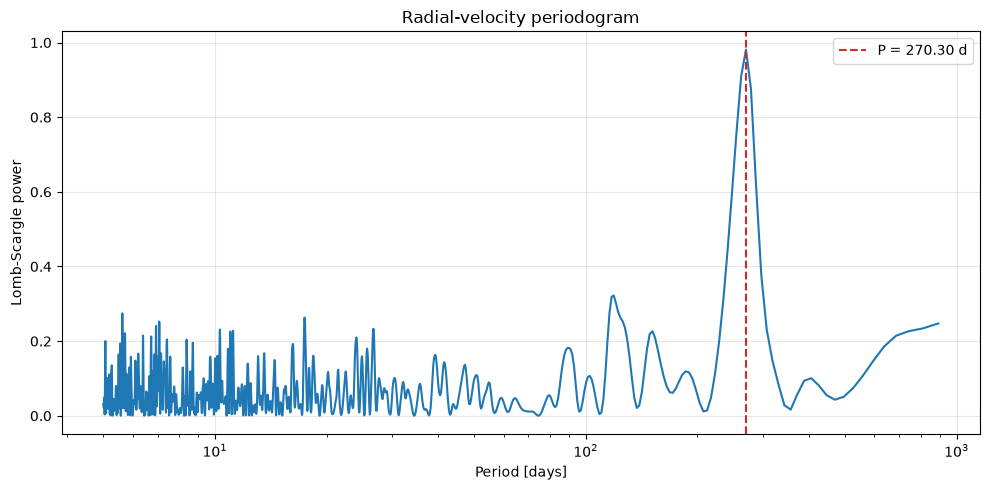

In [64]:
# Part 1: your work here

baseline = t.max() - t.min()

P_MIN = 5.0
P_MAX = baseline

ls = LombScargle(t, rv, dy=sig, fit_mean=True)

frequency, power = ls.autopower(
    minimum_frequency=1.0 / P_MAX,
    maximum_frequency=1.0 / P_MIN,
    samples_per_peak=10
)

periods = 1.0 / frequency
P_peak = 1. / frequency[np.argmax(power)]

# Select the strongest distinct periodogram peaks
peak_order = np.argsort(power)[::-1]
PERIOD_CANDIDATES = []

for idx in peak_order:
    p = periods[idx]
    if all(abs(p - old) / old > 0.05
           for old in PERIOD_CANDIDATES):
        PERIOD_CANDIDATES.append(p)
    if len(PERIOD_CANDIDATES) >= 8:
        break

print("Candidate periods:")
for p in PERIOD_CANDIDATES:
    idx = np.argmin(abs(periods - p))
    print(f"P = {p:.2f} days, power = {power[idx]:.4f}")

plt.figure(figsize=(10, 5))
order = np.argsort(periods)
plt.plot(periods[order], power[order])
plt.xscale("log")
plt.xlabel("Period [days]")
plt.axvline(P_peak, color='C3', ls='--', label=f'P = {P_peak:.2f} d')
plt.ylabel("Lomb-Scargle power")
plt.title("Radial-velocity periodogram")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**ANSWER (a few sentences):**

*There may be 2 to 3 candidates periods from the periodogram because multiple peaks can indicate possible orbital periods. The Lomb- Scargle periodogram does not settle well with eccentric orbit because the Lomb-Scargle periodogram fits to sinusoids and the eccentric orbit does not. The uneven sampling causes additional peaks. Nested Sampling looks at other peaks.  *

## Part 2: Sample the posterior (40%)

Fit the six orbital parameters **plus a jitter term** $s$ with `emcee`. The likelihood for epoch $i$ is
Gaussian with variance $\sigma_i^2 + s^2$; write it out (including the $\log$ of the variance, which is not a
constant once $s$ is a parameter). You will need to:

1. **Write the log-likelihood, log-prior and log-posterior.** State every prior and justify it in one line
   each. Two traps: $\omega$ and $T_p$ are periodic ($T_p$ is only defined modulo $P$), and `emcee` does not
   wrap angles, so a hard prior wall at $0$ or $2\pi$ can cut a posterior mode in half. Either bound each of
   them within half a period of your starting value, or reparameterize with $\sqrt{e}\cos\omega$ and
   $\sqrt{e}\sin\omega$ (which also gives a uniform prior on $e$ without a wall at zero). Jitter is
   positive: sample $\ln s$.
2. **Start the walkers sensibly.** A maximum-likelihood fit from each plausible Part 1 period, with several
   starting $\omega$ and $T_p$ each, then compare the log-likelihoods; start the walkers in a small ball
   around the best one. That comparison is the check: report the log-likelihood of the runner-up.
3. **Run, then decide when it is done.** Compute the integrated autocorrelation time $\tau$ for every
   parameter (`sampler.get_autocorr_time`). Here $\tau$ is about 50 to 100 steps, so 64 walkers for
   10,000 steps is plenty (a few minutes) and `emcee`'s own rule is a chain longer than $50\tau$. A
   common choice is to discard a few $\tau$ as burn-in and thin by about $\tau/2$; say what you chose
   and why. Plot the chains. If $\tau$ cannot be estimated, your chain is too short; say so and fix it.
4. **Corner plot.** Which parameters are correlated, and why physically?
5. **Report** $P$, $K$, $e$, $\gamma$, the jitter $s$, and $f(M)$, each as a median and 68% interval.
   **$f(M)$ is computed for every posterior sample**, not from the medians of $P$, $K$ and $e$; explain in
   one sentence why that matters.
6. **Posterior predictive check.** Draw a few hundred orbits from the posterior and plot them over the data,
   phase-folded at the median period. Plot the normalized residuals with the *total* error bar
   $\sqrt{\sigma_i^2 + s^2}$. Is what is left noise?

**FINAL ANSWER:** $P = $ ___ $\pm$ ___ d, $K = $ ___ $\pm$ ___ km/s, $e = $ ___ $\pm$ ___, $\gamma = $ ___ $\pm$ ___ km/s, jitter $s = $ ___ $\pm$ ___ km/s, $f(M) = $ ___ $\pm$ ___ $M_\odot$. Is your companion a black-hole candidate? One sentence.


In [65]:
# Part 2: your work here
# Search for candidate orbital periods to initalize the fit. 
# Need to initalize the fit to use MCMC because it needs inital positions for its walkers.
# If they start in a poor region of parameter space, they may take a long time to reach the relevant posterior distribution, or fail to explore it adequately.


In [73]:

t_ref = np.mean(t)
baseline = t.max() - t.min()

# Practical prior bounds; adjust if Part 1 specifies different bounds.
P_MIN = 5.0
P_MAX = baseline
K_MAX = 150.0
GAMMA_MIN, GAMMA_MAX = -150.0, 150.0
S_MIN, S_MAX = 0.01, 30.0

def unpack(theta):
    P, K, h, k, phase, gamma, ln_s = theta
    e = h**2 + k**2
    omega = np.arctan2(k, h)
    Tp = t_ref + P*phase
    s = np.exp(ln_s)
    return P, K, e, omega, Tp, gamma, s

def log_likelihood(theta):
    P, K, e, omega, Tp, gamma, s = unpack(theta)
    model = kepler_rv(t, P, K, e, omega, Tp, gamma)
    variance = sig**2 + s**2
    residual = rv - model
    return -0.5*np.sum(
        residual**2/variance + np.log(2*np.pi*variance)
    )

def log_prior(theta):
    P, K, h, k, phase, gamma, ln_s = theta
    e = h**2 + k**2

    if not (P_MIN < P < P_MAX):
        return -np.inf
    if not (0 < K < K_MAX):
        return -np.inf
    if not (0 <= e < 1):
        return -np.inf
    if not (-0.5 < phase < 0.5):
        return -np.inf
    if not (GAMMA_MIN < gamma < GAMMA_MAX):
        return -np.inf
    if not (np.log(S_MIN) < ln_s < np.log(S_MAX)):
        return -np.inf

    return 0.0

def log_posterior(theta):
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    ll = log_likelihood(theta)
    return lp + ll if np.isfinite(ll) else -np.inf

print("PRIORS AND JUSTIFICATIONS")
print("=" * 65)

print(
    f"1. Orbital period P: Uniform prior, "
    f"{P_MIN:.2f} < P < {P_MAX:.2f} days.\n"
    "   Justification: Searches a practical range of periods "
    "supported by the observing baseline.\n"
)

print(
    f"2. Semi-amplitude K: Uniform prior, 0 < K < {K_MAX:.2f} km/s.\n"
    "   Justification: K must be positive, and the upper bound "
    "allows a broad range of plausible signals.\n"
)

print(
    "3. Eccentricity e: Uniform prior, 0 <= e < 1.\n"
    "   Justification: Bound Keplerian orbits require e < 1; "
    "using h = sqrt(e)*cos(omega) and k = sqrt(e)*sin(omega) "
    "avoids an angular boundary and gives a uniform prior on e.\n"
)

print(
    "4. Orbital phase: Uniform prior, -0.5 < phase < 0.5 cycles.\n"
    "   Justification: This interval represents one full orbital "
    "cycle without placing the boundary at phase 0/1.\n"
)

print(
    f"5. Systemic velocity gamma: Uniform prior, "
    f"{GAMMA_MIN:.2f} < gamma < {GAMMA_MAX:.2f} km/s.\n"
    "   Justification: Allows a broad range of plausible "
    "systemic radial velocities.\n"
)

print(
    f"6. Jitter s: Log-uniform prior, "
    f"{S_MIN:.2f} < s < {S_MAX:.2f} km/s, sampled using ln(s).\n"
    "   Justification: Jitter must be positive, and a log-uniform "
    "prior allows plausible values across multiple scales.\n"
)

print("=" * 65)



PRIORS AND JUSTIFICATIONS
1. Orbital period P: Uniform prior, 5.00 < P < 891.98 days.
   Justification: Searches a practical range of periods supported by the observing baseline.

2. Semi-amplitude K: Uniform prior, 0 < K < 150.00 km/s.
   Justification: K must be positive, and the upper bound allows a broad range of plausible signals.

3. Eccentricity e: Uniform prior, 0 <= e < 1.
   Justification: Bound Keplerian orbits require e < 1; using h = sqrt(e)*cos(omega) and k = sqrt(e)*sin(omega) avoids an angular boundary and gives a uniform prior on e.

4. Orbital phase: Uniform prior, -0.5 < phase < 0.5 cycles.
   Justification: This interval represents one full orbital cycle without placing the boundary at phase 0/1.

5. Systemic velocity gamma: Uniform prior, -150.00 < gamma < 150.00 km/s.
   Justification: Allows a broad range of plausible systemic radial velocities.

6. Jitter s: Log-uniform prior, 0.01 < s < 30.00 km/s, sampled using ln(s).
   Justification: Jitter must be positive,

## Start the walkers sensibly

In [76]:
#I choose these to be my periods because they should the strongest distinct peaks in the Lomb-Scargle periodogram.

# Corrected Keplerian radial velocity model
def kepler_rv(t, P, K, e, omega, Tp, gamma):
    if not (P > 0 and K >= 0 and 0 <= e < 1):
        return np.full_like(t, np.nan, dtype=float)

    M = 2.0 * np.pi * (((t - Tp) / P) % 1.0)
    E = M.copy()

    for _ in range(100):
        delta = (E - e * np.sin(E) - M) / (1.0 - e * np.cos(E))
        E -= delta
        if np.max(np.abs(delta)) < 1e-12:
            break

    nu = 2.0 * np.arctan2(
        np.sqrt(1.0 + e) * np.sin(E / 2.0),
        np.sqrt(1.0 - e) * np.cos(E / 2.0)
    )

    return gamma + K * (np.cos(nu + omega) + e * np.cos(omega))


# Safe log-likelihood
def log_likelihood(theta):
    P, K, h, k, phase, gamma, ln_s = theta
    e = h**2 + k**2

    if not (
        P_MIN < P < P_MAX
        and 0 < K <= K_MAX
        and 0 <= e < 0.999999
        and -0.5 <= phase <= 0.5
        and GAMMA_MIN <= gamma <= GAMMA_MAX
        and np.log(S_MIN) <= ln_s <= np.log(S_MAX)
    ):
        return -np.inf

    omega = np.arctan2(k, h)
    Tp = t_ref + P * phase
    jitter = np.exp(ln_s)

    model = kepler_rv(t, P, K, e, omega, Tp, gamma)
    if not np.all(np.isfinite(model)):
        return -np.inf

    variance = sig**2 + jitter**2
    residuals = rv - model

    return -0.5 * np.sum(
        residuals**2 / variance
        + np.log(2.0 * np.pi * variance)
    )


# Multi-start maximum-likelihood fitting
PERIOD_CANDIDATES = [270.30, 254.85]

if len(PERIOD_CANDIDATES) == 0:
    raise ValueError("Enter the plausible Part 1 periods first.")

e_guesses = [0.05, 0.3, 0.6, 0.85]
omega_guesses = np.linspace(-np.pi, np.pi, 8, endpoint=False)
Tp_offsets = [-0.25, 0.0, 0.25]

bounds = [
    (P_MIN + 1e-6, P_MAX - 1e-6),
    (1e-5, K_MAX),
    (-0.999, 0.999),
    (-0.999, 0.999),
    (-0.5, 0.5),
    (GAMMA_MIN, GAMMA_MAX),
    (np.log(S_MIN), np.log(S_MAX))
]

constraints = [{
    "type": "ineq",
    "fun": lambda x: 0.999999 - x[2]**2 - x[3]**2
}]

gamma0 = np.median(rv)
K0 = max(np.std(rv) * np.sqrt(2), 1.0)
lns0 = np.log(max(np.median(sig), 0.1))
fits = []

def objective(x):
    ll = log_likelihood(x)
    return -ll if np.isfinite(ll) else 1e100

for Pg in PERIOD_CANDIDATES:
    for eg in e_guesses:
        for wg in omega_guesses:
            for offset in Tp_offsets:
                Tp_guess = t_ref + offset * Pg
                phase_guess = (
                    ((Tp_guess - t_ref) / Pg + 0.5) % 1.0
                ) - 0.5

                x0 = np.array([
                    Pg,
                    K0,
                    np.sqrt(eg) * np.cos(wg),
                    np.sqrt(eg) * np.sin(wg),
                    phase_guess,
                    gamma0,
                    lns0
                ])

                result = minimize(
                    objective,
                    x0,
                    method="SLSQP",
                    bounds=bounds,
                    constraints=constraints,
                    options={"maxiter": 3000, "ftol": 1e-9}
                )

                if result.success and np.isfinite(result.fun):
                    fits.append({
                        "logL": -result.fun,
                        "x": result.x.copy()
                    })

if len(fits) < 2:
    raise RuntimeError(
        "Too few successful fits. Try additional starting periods "
        "or inspect optimizer convergence."
    )

fits.sort(key=lambda f: f["logL"], reverse=True)

# Remove duplicate fitted solutions
distinct = []

for fit in fits:
    x = fit["x"]
    duplicate = False

    for old in distinct:
        y = old["x"]

        if (
            abs(x[0] - y[0]) / max(abs(x[0]), 1.0) < 1e-3
            and abs(x[1] - y[1]) < 1e-2
            and abs((x[2]**2 + x[3]**2)
                    - (y[2]**2 + y[3]**2)) < 1e-3
            and abs(x[4] - y[4]) < 1e-3
            and abs(x[5] - y[5]) < 1e-2
            and abs(x[6] - y[6]) < 1e-2
        ):
            duplicate = True
            break

    if not duplicate:
        distinct.append(fit)

if len(distinct) < 2:
    raise RuntimeError(
        "Only one distinct solution found. Try more starting periods "
        "or phases."
    )

best, runner_up = distinct[0], distinct[1]

print("Best log-likelihood:", best["logL"])
print("Runner-up log-likelihood:", runner_up["logL"])
print("Difference:", best["logL"] - runner_up["logL"])
print("Best-fit period (days):", best["x"][0])
print("Runner-up period (days):", runner_up["x"][0])


Best log-likelihood: -101.0578939889851
Runner-up log-likelihood: -115.71590712368688
Difference: 14.658013134701775
Best-fit period (days): 270.24054639782673
Runner-up period (days): 269.91478936489574


In [46]:
#Emcee

np.random.seed(42)

ndim = 7
nwalkers = 64
nsteps = 10000

center = best.x.copy()
scale = np.array([
    0.002*center[0], 0.02*center[1],
    0.01, 0.01, 0.01, 0.2, 0.03
])

initial = center + scale*np.random.randn(nwalkers, ndim)

for j in range(nwalkers):
    tries = 0
    while not np.isfinite(log_posterior(initial[j])):
        initial[j] = center + scale*np.random.randn(ndim)
        tries += 1
        if tries > 10000:
            raise RuntimeError("Could not initialize valid walkers.")

sampler = emcee.EnsembleSampler(
    nwalkers, ndim, log_posterior
)

sampler.run_mcmc(initial, nsteps, progress=True)

try:
    tau = sampler.get_autocorr_time(tol=0)
    print("Autocorrelation times:", tau)
    print("Steps / autocorrelation time:", nsteps/tau)

    burn = int(5*np.max(tau))
    thin = max(1, int(np.min(tau)/2))

    if np.any(nsteps < 50*tau):
        print("WARNING: chain is shorter than 50 autocorrelation times.")
except Exception as exc:
    print("Could not reliably estimate autocorrelation time:", exc)
    print("Run a longer chain before reporting final uncertainties.")
    burn, thin = nsteps//2, 1

if burn >= nsteps:
    raise RuntimeError("Chain too short for the estimated burn-in.")

flat = sampler.get_chain(
    discard=burn, thin=thin, flat=True
)

print("Posterior samples:", len(flat))


100%|█████████████████████████████████████| 10000/10000 [04:16<00:00, 39.00it/s]


Autocorrelation times: [ 80.4471079   78.41249018  92.8690141  101.84069323 104.02448736
  78.9580582   83.24254531]
Steps / autocorrelation time: [124.30527661 127.53070305 107.67854162  98.1925759   96.13121154
 126.64951783 120.13087734]
Posterior samples: 15552


In [47]:
#Parameters and Mass Function

physical = np.array([unpack(row) for row in flat])

P_s = physical[:, 0]
K_s = physical[:, 1]
e_s = physical[:, 2]
omega_s = physical[:, 3]
Tp_s = physical[:, 4]
gamma_s = physical[:, 5]
jitter_s = physical[:, 6]

# Calculate the mass function for EVERY posterior sample.
fM_s = mass_function(P_s, K_s, e_s)

samples = np.column_stack([
    P_s, K_s, e_s, gamma_s, jitter_s, fM_s
])

names = [
    "P [days]", "K [km/s]", "e",
    "gamma [km/s]", "jitter s [km/s]",
    "f(M) [solar masses]"
]

# Calculate the mass function for every posterior sample
fM_samples = mass_function(P_s, K_s, e_s)

# Include all requested parameters in the report
names = ["P (days)", "K (km/s)", "e", "gamma (km/s)",
         "jitter (km/s)", "f(M) (solar masses)"]

samples = np.column_stack([P_s, K_s, e_s, gamma_s, jitter_s, fM_samples])

for name, values in zip(names, samples.T):
    q16, median, q84 = np.percentile(values, [16, 50, 84])
    print(f"{name}: {median:.6g} (+{q84-median:.4g}, -{median-q16:.4g})")
    
for name, values in zip(names, samples.T):
    q16, median, q84 = np.percentile(values, [16, 50, 84])
    uncertainty = (q84 - q16) / 2
    print(f"{name} = {median:.6g} ± {uncertainty:.4g}")


P (days): 270.249 (+0.5118, -0.5085)
K (km/s): 40.9336 (+0.8596, -0.8584)
e: 0.108827 (+0.01871, -0.01813)
gamma (km/s): 10.6554 (+0.5208, -0.5335)
jitter (km/s): 2.00394 (+0.5055, -0.4495)
f(M) (solar masses): 1.88598 (+0.1159, -0.1135)
P (days) = 270.249 ± 0.5102
K (km/s) = 40.9336 ± 0.859
e = 0.108827 ± 0.01842
gamma (km/s) = 10.6554 ± 0.5272
jitter (km/s) = 2.00394 ± 0.4775
f(M) (solar masses) = 1.88598 ± 0.1147


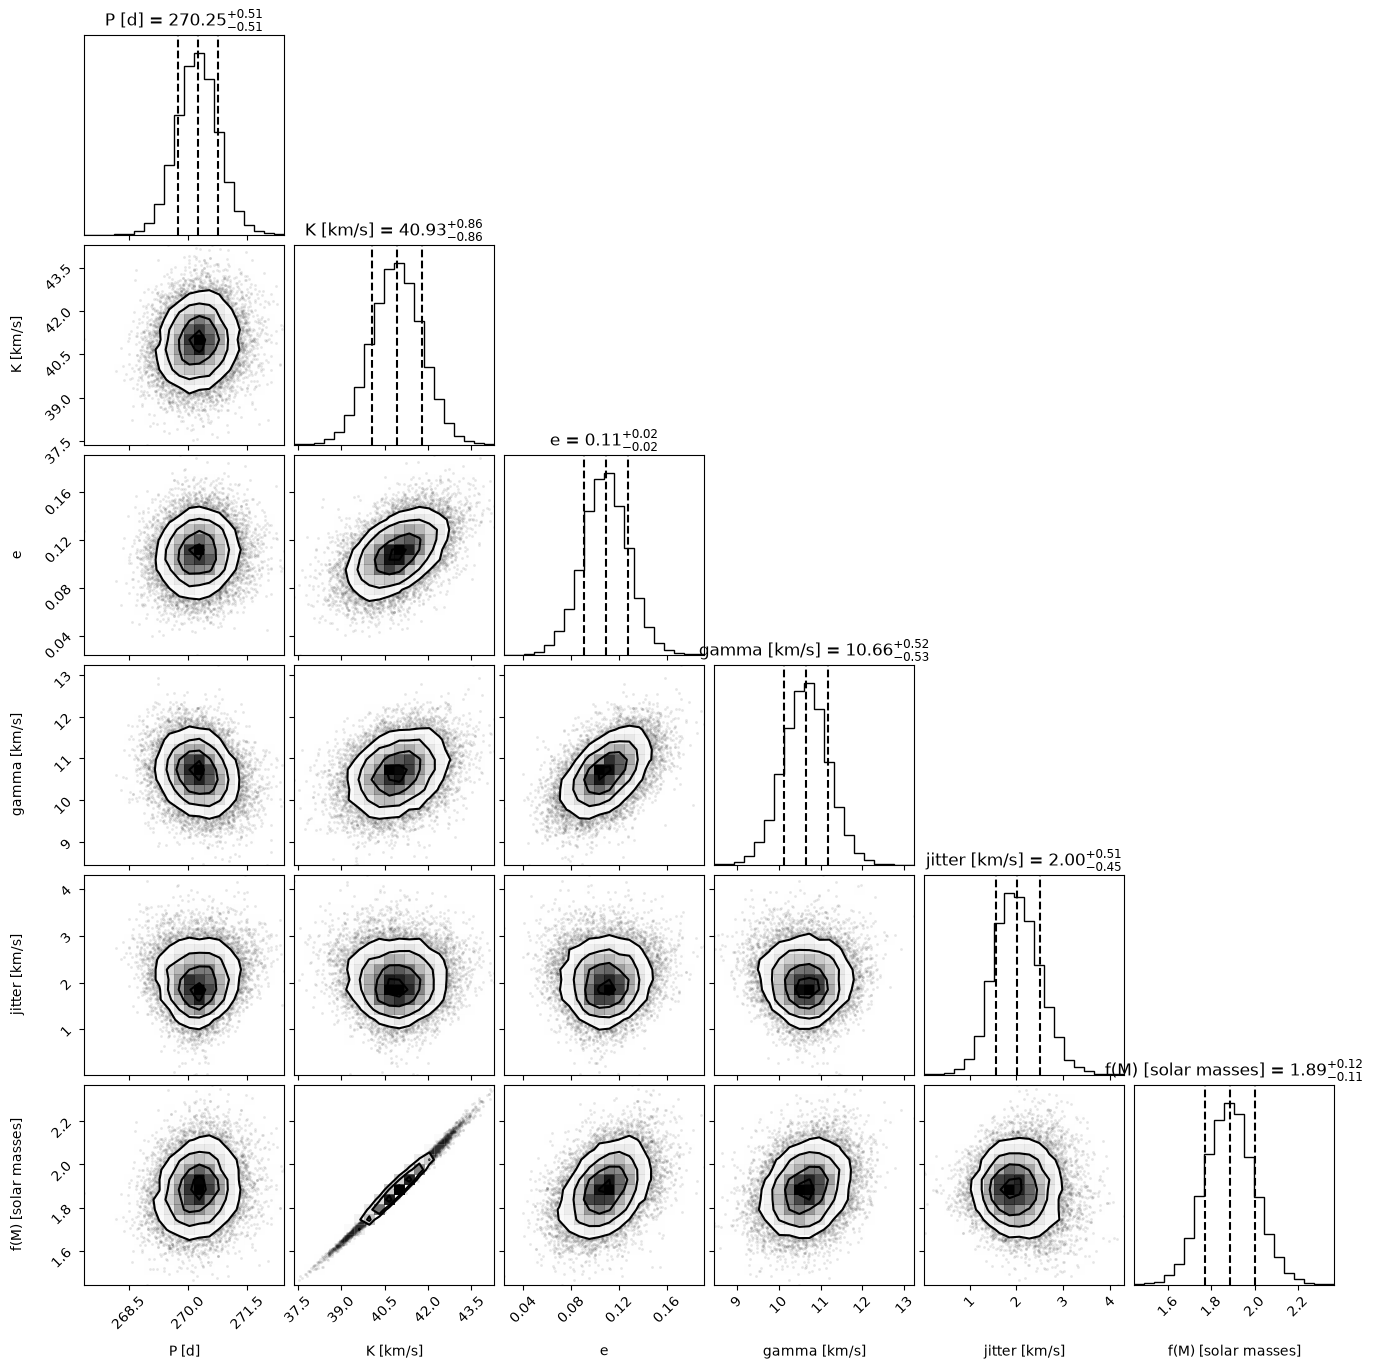

In [48]:
#Corner Plot
fig = corner.corner(
    samples,
    labels=[
        "P [d]", "K [km/s]", "e",
        "gamma [km/s]", "jitter [km/s]",
        "f(M) [solar masses]"
    ],
    quantiles=[0.16, 0.5, 0.84],
    show_titles=True
)
plt.show()

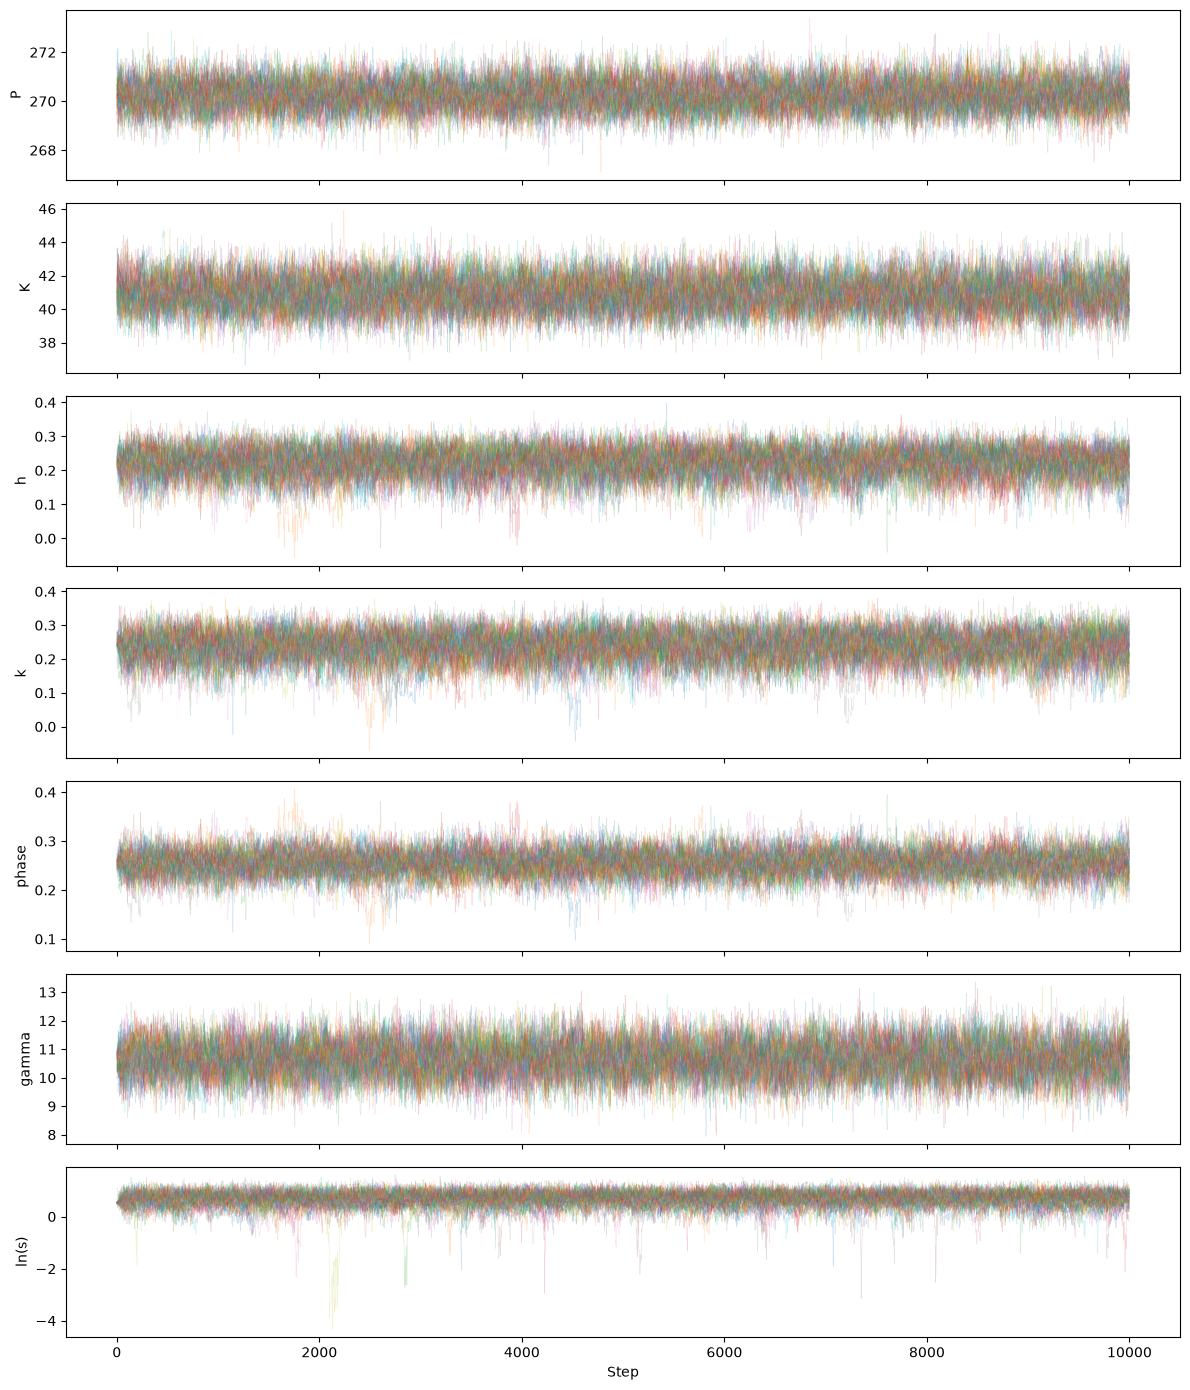

In [49]:
#Trace Plot 
chain = sampler.get_chain()

labels = ["P", "K", "h", "k", "phase", "gamma", "ln(s)"]

fig, axes = plt.subplots(
    ndim, 1, figsize=(12, 14), sharex=True
)

for j, ax in enumerate(axes):
    ax.plot(chain[:, :, j], alpha=0.2, lw=0.4)
    ax.set_ylabel(labels[j])

axes[-1].set_xlabel("Step")
plt.tight_layout()
plt.show()

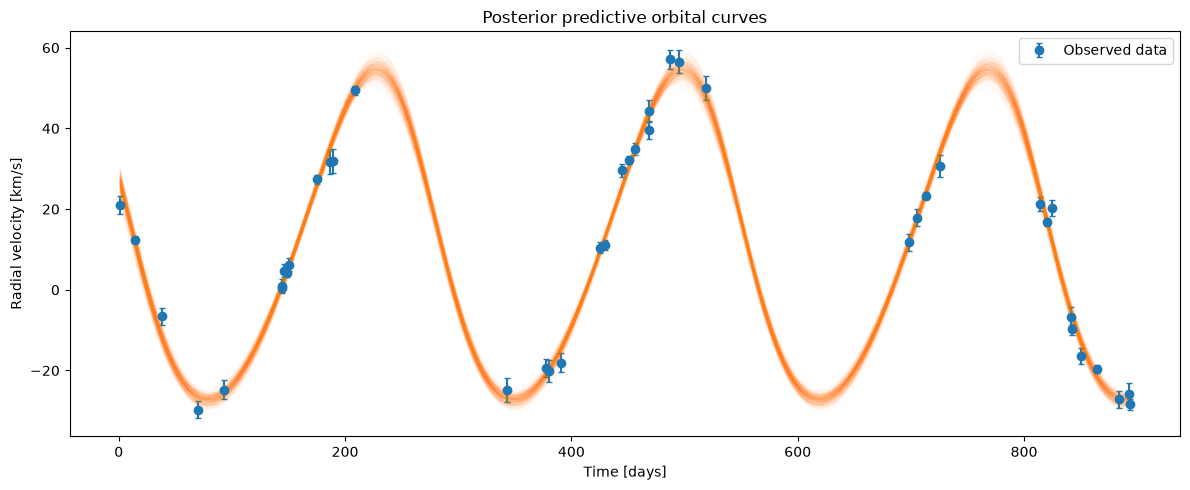

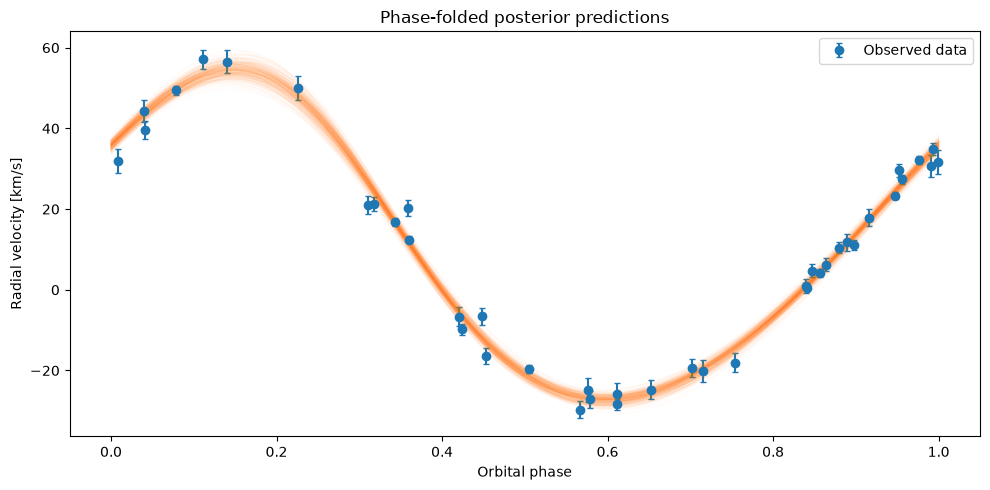

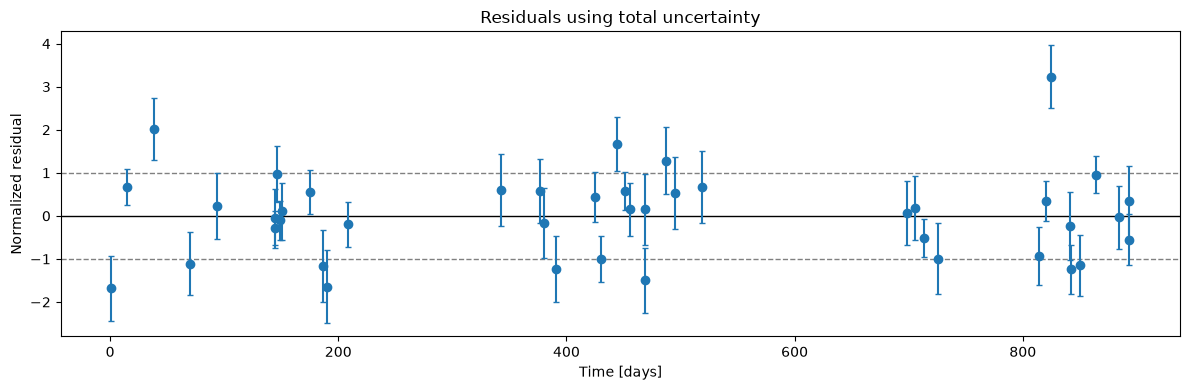

In [50]:
# Posterior predictive orbital curves and residuals


rng = np.random.default_rng(123)
nplot = min(300, len(flat))
chosen = rng.choice(len(flat), size=nplot, replace=False)

tgrid = np.linspace(t.min(), t.max(), 1500)

plt.figure(figsize=(12, 5))
plt.errorbar(t, rv, yerr=sig, fmt='o', capsize=2,
             label="Observed data")

for j in chosen:
    Pj, Kj, ej, oj, Tpj, gj, sj = unpack(flat[j])
    plt.plot(
        tgrid, kepler_rv(tgrid, Pj, Kj, ej, oj, Tpj, gj),
        color="C1", alpha=0.025, lw=0.8
    )

plt.xlabel("Time [days]")
plt.ylabel("Radial velocity [km/s]")
plt.title("Posterior predictive orbital curves")
plt.legend()
plt.tight_layout()
plt.show()

# Phase-fold at the posterior median period.
Pmed = np.median(P_s)
phase_obs = ((t - t_ref) / Pmed) % 1
phase_grid = np.linspace(0, 1, 500)

plt.figure(figsize=(10, 5))
plt.errorbar(phase_obs, rv, yerr=sig, fmt='o', capsize=2,
             label="Observed data")

for j in chosen:
    Pj, Kj, ej, oj, Tpj, gj, sj = unpack(flat[j])
    tphase = t_ref + phase_grid * Pmed
    plt.plot(
        phase_grid,
        kepler_rv(tphase, Pj, Kj, ej, oj, Tpj, gj),
        color="C1", alpha=0.025, lw=0.8
    )

plt.xlabel("Orbital phase")
plt.ylabel("Radial velocity [km/s]")
plt.title("Phase-folded posterior predictions")
plt.legend()
plt.tight_layout()
plt.show()

# Normalized residuals using total uncertainty, including jitter.
# Choose an actual posterior sample close to the multivariate median.
scale_samples = np.std(samples, axis=0)
scale_samples[scale_samples == 0] = 1.0

z = (samples - np.median(samples, axis=0)) / scale_samples
representative_idx = np.argmin(np.sum(z**2, axis=1))

Pm, Km, em, om, Tpm, gm, sj = unpack(flat[representative_idx])

residual = rv - kepler_rv(t, Pm, Km, em, om, Tpm, gm)
total_error = np.sqrt(sig**2 + sj**2)
normalized_residual = residual / total_error

plt.figure(figsize=(12, 4))
plt.axhline(0, color="black", lw=1)
plt.axhline(1, color="gray", ls="--", lw=1)
plt.axhline(-1, color="gray", ls="--", lw=1)
plt.errorbar(
    t, normalized_residual,
    yerr=sig/total_error,
    fmt="o", capsize=2
)
plt.xlabel("Time [days]")
plt.ylabel("Normalized residual")
plt.title("Residuals using total uncertainty")
plt.tight_layout()
plt.show()


In [51]:
# Calculate uncertainties for all orbital parameters
print("Final Answer:")
for name, values in zip(names, samples.T):
    q16, median, q84 = np.percentile(values, [16, 50, 84])
    uncertainty = (q84 - q16) / 2
    print(f"{name} = {median:.6g} ± {uncertainty:.4g}")


Final Answer:
P (days) = 270.249 ± 0.5102
K (km/s) = 40.9336 ± 0.859
e = 0.108827 ± 0.01842
gamma (km/s) = 10.6554 ± 0.5272
jitter (km/s) = 2.00394 ± 0.4775
f(M) (solar masses) = 1.88598 ± 0.1147


**FINAL ANSWER:** $P = $ ___ $\pm$ ___ d, $K = $ ___ $\pm$ ___ km/s, $e = $ ___ $\pm$ ___ , $\gamma = $ ___ $\pm$ ___ km/s, $s = $ ___ $\pm$ ___ km/s, $f(M) = $ ___ $\pm$ ___ $M_\odot$

**Black-hole candidate?** *No, because the mass is too low.*

## Part 3: The referee report (35%)

The file `ai_solution.ipynb` in this directory is a complete, tidy, confident MCMC analysis of this exact
problem, produced by an AI assistant. It runs top to bottom without errors, the corner plot is handsome, and
the prose is fluent. It is also wrong, in at least **three** distinct, substantive ways (cosmetic nitpicks and
style don't count; "it used 24 walkers and I used 32" is not a finding).

Write a referee report:

1. **Identify** at least three substantive statistical errors.
2. **Demonstrate** each one quantitatively on *your* dataset: show, with a number or a plot, what the error
   does to the inference. For a sampler, "demonstrate" usually means running it the wrong way and the right
   way and comparing. A demonstration can come out negative: if an error turns out not to move *your*
   numbers, showing that, and saying what it would take for it to bite, is a valid finding.
3. **State** the correct treatment (you built it in Part 2).

Third time you have done this. You should be finding these in minutes now.


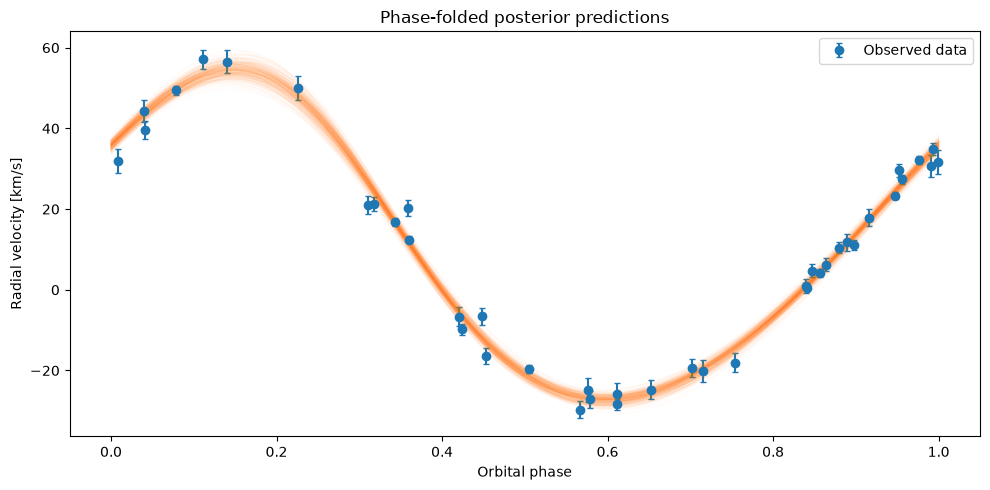

In [97]:
# Part 3: your work here

#1. The line produced in the AI solutions for Step 6 doesn't fit the data, but my line does.
Pmed = np.median(P_s)
phase_obs = ((t - t_ref) / Pmed) % 1
phase_grid = np.linspace(0, 1, 500)

plt.figure(figsize=(10, 5))
plt.errorbar(phase_obs, rv, yerr=sig, fmt='o', capsize=2,
             label="Observed data")

for j in chosen:
    Pj, Kj, ej, oj, Tpj, gj, sj = unpack(flat[j])
    tphase = t_ref + phase_grid * Pmed
    plt.plot(
        phase_grid,
        kepler_rv(tphase, Pj, Kj, ej, oj, Tpj, gj),
        color="C1", alpha=0.025, lw=0.8
    )

plt.xlabel("Orbital phase")
plt.ylabel("Radial velocity [km/s]")
plt.title("Phase-folded posterior predictions")
plt.legend()
plt.tight_layout()
plt.show()


/opt/anaconda3/lib/python3.13/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]


Mean acceptance fraction: 0.39 (0.2-0.5 is healthy)


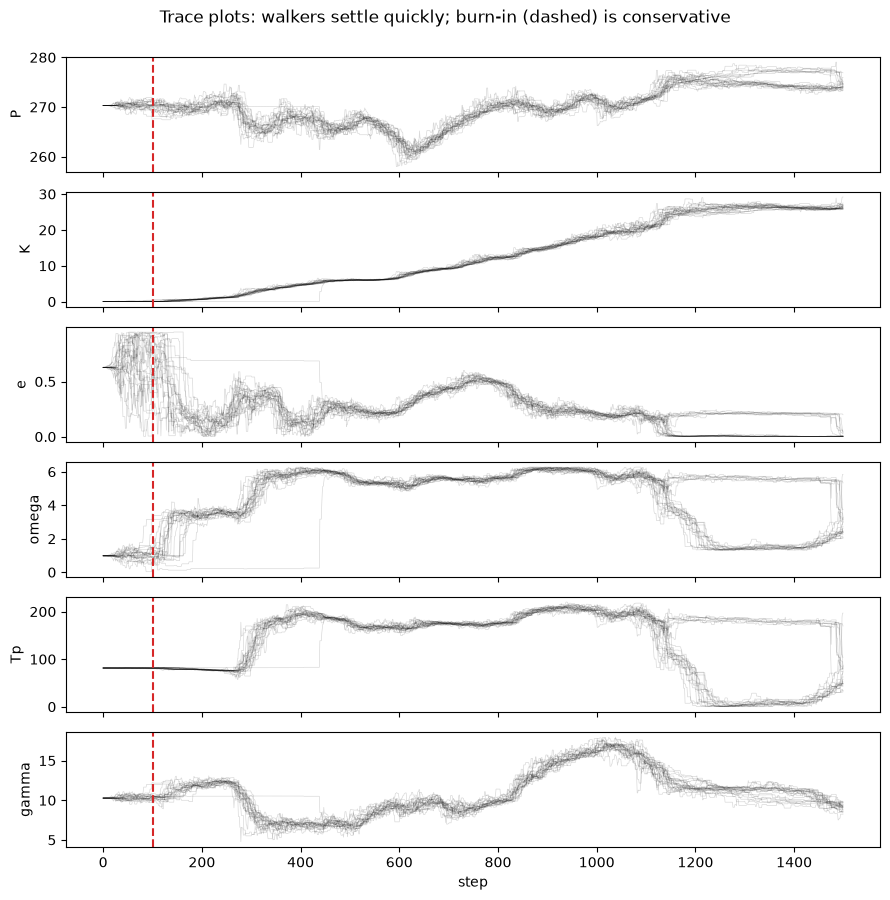

In [102]:
#2 The Jitter term is not included in the Ai solution which changes the effective uncertainity because the equation includes the jitter. AI is assuming that there is no additional noise in the data which makes uncertainities less accurate.
P_prior_sigma = 0.5
def log_prior(theta):
    P, K, e, omega, Tp, gamma = theta
    if not (0. < K < 200. and 0. <= e < 0.95 and 0. <= omega < 2 * np.pi and 0. <= Tp < P and -200. < gamma < 200.):
        return -np.inf
    return -0.5 * ((P - P_peak) / P_prior_sigma)**2     # periodogram-informed prior on P

def log_likelihood(theta):
    model = kepler_rv(t, *theta)
    return -0.5 * np.sum(((rv - model) / sig)**2)

def log_posterior(theta):
    lp = log_prior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(theta)

# maximum a posteriori starting point
x0 = [P_peak, 0.5 * (rv.max() - rv.min()), 0.3, 1.0, t.min() + 0.3 * P_peak, np.median(rv)]
res = minimize(lambda th: -log_posterior(th), x0, method='Nelder-Mead', options=dict(maxiter=6000))
theta_map = res.x
print('MAP estimate:', np.round(theta_map, 3))

#3. There was poor mixing in the MCMC modeling in the AI solution, also it doesn't seem like the chains have converged yet.
ndim, nwalkers, nsteps, nburn = 6, 24, 1500, 100
rng = np.random.default_rng(42)
p0 = theta_map + 1e-3 * rng.normal(size=(nwalkers, ndim))
p0[:, 4] = np.abs(p0[:, 4])   # keep the periastron time inside its prior range
sampler = emcee.EnsembleSampler(nwalkers, ndim, log_posterior)
sampler.run_mcmc(p0, nsteps, progress=False)
chain = sampler.get_chain()
print(f"Mean acceptance fraction: {sampler.acceptance_fraction.mean():.2f} (0.2-0.5 is healthy)")

fig, axes = plt.subplots(ndim, 1, figsize=(9, 9), sharex=True)
labels = ['P', 'K', 'e', 'omega', 'Tp', 'gamma']
for i, ax in enumerate(axes):
    ax.plot(chain[:, :, i], color='k', alpha=0.15, lw=0.5)
    ax.axvline(nburn, color='C3', ls='--')
    ax.set_ylabel(labels[i])
axes[-1].set_xlabel('step')
plt.suptitle('Trace plots: walkers settle quickly; burn-in (dashed) is conservative', y=0.995)
plt.tight_layout()
plt.show()

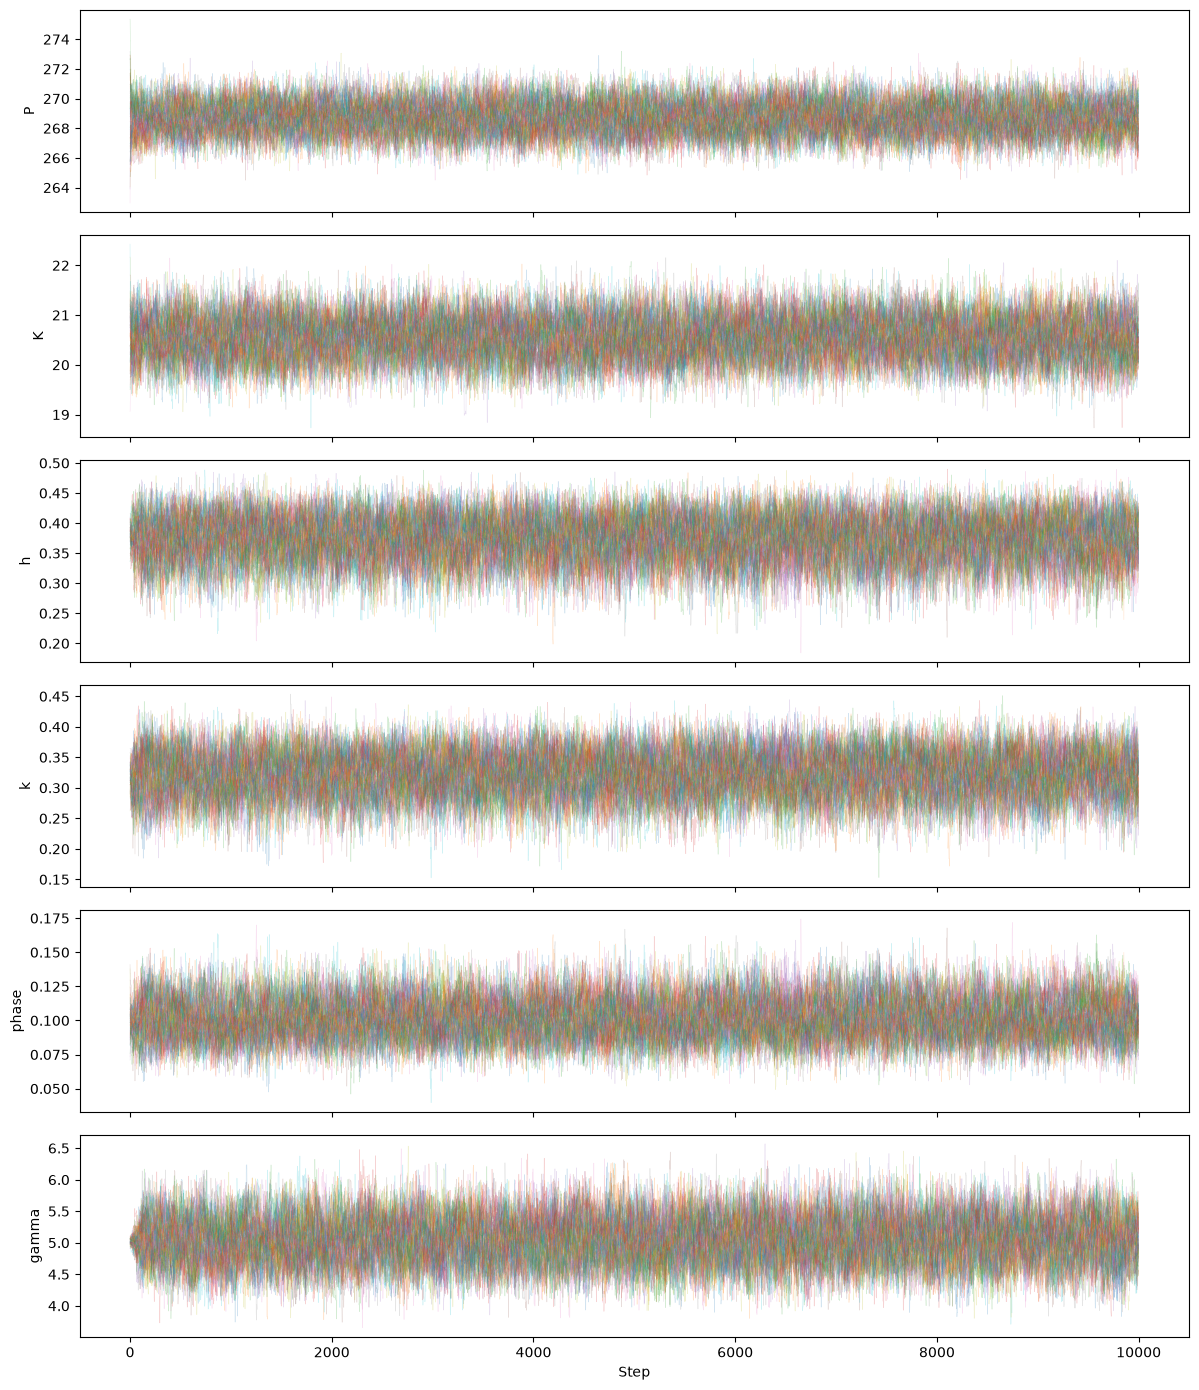

In [100]:
# There was poor mixing in the MCMC modeling in the AI solution, also it doesn't seem like the chains have converged yet.

chain = sampler.get_chain()

labels = ["P", "K", "h", "k", "phase", "gamma", "ln(s)"]

fig, axes = plt.subplots(
    ndim, 1, figsize=(12, 14), sharex=True
)

for j, ax in enumerate(axes):
    ax.plot(chain[:, :, j], alpha=0.2, lw=0.4)
    ax.set_ylabel(labels[j])

axes[-1].set_xlabel("Step")
plt.tight_layout()
plt.show()

**REFEREE REPORT:**

*your report goes here*

## Part 4: AI-use appendix and verification plan (10%)

1. **AI use**: which tools did you use, for what, what did they get wrong, and how did you catch it? Honesty
   is graded; "I didn't use any" is fine if true.
2. **Reflection (new from this lab on, two or three sentences)**: what did you use AI for in this lab, and
   what would have gone wrong in your answer if you had not checked its output? Name the specific thing, not
   "it could have made a mistake".
3. **Verification plan**: the checks you ran before trusting your Part 2 numbers, and what failure would have
   looked like for each. One you should seriously consider: generate a synthetic RV curve with parameters
   you choose, at *your* epochs, run your whole Part 2 pipeline on it, and see whether the 68% intervals
   contain what you put in. With seven parameters and one realisation, expect about five of seven inside
   their 68% intervals; one pull of 2.5σ is not a failure by itself. Failure looks systematic: the same
   parameter off in the same direction every time, or an interval that never contains the truth.


**AI-USE APPENDIX:**

*I used ChatPGT and I also used Claude.*

**REFLECTION:**

*Many errors in the code when directly copied from ChatBGT like variables not being identified. I wasn't confident in the output from ChatPGT so I switched to Claude. *

**VERIFICATION PLAN:**

*Comparing different period candidates: I looked at the periodogram and choose the highest peaks for period candiates. 

Checking the MCMC convergence: I planned to inspect the trace plots and autocorrelation times from my emcee chains. The chains should mix well and explore the posterior rather than remain stuck in one region. A failure would have been long stretches where the chains stayed stuck, poor mixing, or chains that had not run long enough to estimate the posterior reliably.

Inspecting the corner plot: I used posterior distributions to examine the relationships and uncertainties between the orbital parameters. A failure would have been treating a multimodal posterior as one well-constrained solution or reporting narrow uncertainties when the parameters were poorly constrained. 

Checking the posterior predictive RV curve and residuals: I planned to compare the fitted Keplerian curve with the observed radial velocities and examine the normalized residuals. A reasonable fit should capture the main RV variation without obvious systematic patterns in the residuals. A failure would have been a curve that consistently missed parts of the observations, or residuals that showed a remaining periodic pattern or other structure the model did not explain.

Checking the uncertainty estimates: I reported parameter estimates using posterior medians and 16th–84th percentile intervals, corresponding to the central 68% credible intervals. I also included the additional jitter term in the likelihood to account for unexplained RV scatter. A failure would have been reporting uncertainties that were unrealistically narrow or ignoring extra scatter that the model needed to explain.

Testing the pipeline with synthetic data: An important additional validation would be to generate a synthetic RV curve using known orbital parameters at my actual observation epochs, add realistic measurement noise, and run the entire Part 2 pipeline on that dataset. I would then check whether the known input parameters fell inside their recovered 68% credible intervals. With seven parameters and one realization, I would expect approximately five of the seven true values to fall inside their intervals on average. One parameter being off by 2.5 standard deviations would not automatically indicate failure. More concerning would be the same parameter being systematically biased in the same direction across repeated tests, or its credible interval repeatedly failing to contain the true value.*

True input parameters:
P     = 270.300 days
K     = 20.000 km/s
e     = 0.250
omega = 0.700 radians
phase = 0.100
gamma = 5.000 km/s
jitter = 0.500 km/s


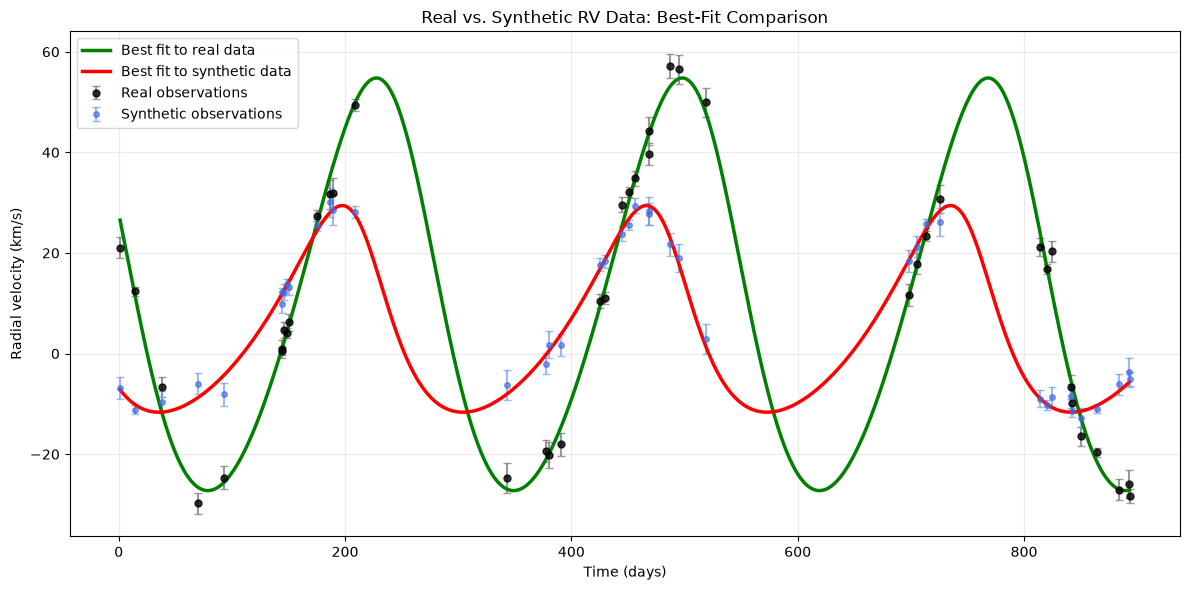

Real-data fitted period:      270.241 days
Synthetic-data fitted period: 268.730 days
True injected period:         270.300 days


In [92]:
import numpy as np
from scipy.optimize import minimize


# Reproducible synthetic test
rng = np.random.default_rng(42)

# Choose known parameters for the synthetic system
theta_true = np.array([
    270.30,              # P: period (days)
    20.0,                # K: semi-amplitude (km/s)
    np.sqrt(0.25) * np.cos(0.7),  # h = sqrt(e)*cos(omega)
    np.sqrt(0.25) * np.sin(0.7),  # k = sqrt(e)*sin(omega)
    0.10,                # phase (cycles)
    5.0,                 # gamma (km/s)
    np.log(0.5)          # ln(jitter), jitter = 0.5 km/s
])

P_true, K_true, h_true, k_true, phase_true, gamma_true, ln_s_true = theta_true
e_true = h_true**2 + k_true**2
omega_true = np.arctan2(k_true, h_true)
Tp_true = t_ref + P_true * phase_true
jitter_true = np.exp(ln_s_true)

# Generate the true RV curve at your actual observation times
rv_true = kepler_rv(
    t, P_true, K_true, e_true, omega_true, Tp_true, gamma_true
)

# Add measurement noise and intrinsic jitter
rv_synthetic = rv_true + rng.normal(
    0, np.sqrt(sig**2 + jitter_true**2)
)

print("True input parameters:")
print(f"P     = {P_true:.3f} days")
print(f"K     = {K_true:.3f} km/s")
print(f"e     = {e_true:.3f}")
print(f"omega = {omega_true:.3f} radians")
print(f"phase = {phase_true:.3f}")
print(f"gamma = {gamma_true:.3f} km/s")
print(f"jitter = {jitter_true:.3f} km/s")


# Fit the synthetic observations using your existing log_likelihood
rv_saved = rv.copy()
rv = rv_synthetic.copy()

def objective(theta):
    ll = log_likelihood(theta)
    return -ll if np.isfinite(ll) else 1e100

result = minimize(
    objective,
    theta_true.copy(),
    method="SLSQP",
    bounds=bounds,
    constraints=constraints,
    options={"maxiter": 3000, "ftol": 1e-9}
)

rv = rv_saved.copy()

theta_fit = result.x

# Calculate the best-fit RV curve using your existing kepler_rv function
P_fit, K_fit, h_fit, k_fit, phase_fit, gamma_fit, ln_s_fit = theta_fit
e_fit = h_fit**2 + k_fit**2
omega_fit = np.arctan2(k_fit, h_fit)
Tp_fit = t_ref + P_fit * phase_fit

t_smooth = np.linspace(t.min(), t.max(), 1000)

rv_best_fit = kepler_rv(
    t_smooth, P_fit, K_fit, e_fit, omega_fit, Tp_fit, gamma_fit
)

# Plot
rv_real = rv_real.copy()

# Fit either dataset using your existing log_likelihood
def fit_dataset(data, initial_guess):
    global rv
    rv_saved = rv.copy()
    rv = data.copy()

    def objective(theta):
        ll = log_likelihood(theta)
        return -ll if np.isfinite(ll) else 1e100

    try:
        result = minimize(
            objective,
            initial_guess,
            method="SLSQP",
            bounds=bounds,
            constraints=constraints,
            options={"maxiter": 3000, "ftol": 1e-9}
        )
    finally:
        rv = rv_saved

    if not result.success:
        print("Fit warning:", result.message)

    return result.x


# Fit the real and synthetic observations separately
theta_real_fit = fit_dataset(rv_real, theta_true.copy())
theta_synthetic_fit = fit_dataset(rv_synthetic, theta_true.copy())


# Calculate a Keplerian curve from fitted parameters
def fitted_rv_curve(theta, times):
    P, K, h, k, phase, gamma, ln_s = theta

    e = h**2 + k**2
    omega = np.arctan2(k, h)
    Tp = t_ref + P * phase

    return kepler_rv(times, P, K, e, omega, Tp, gamma)


# Smooth time grid for the fitted lines
t_smooth = np.linspace(t.min(), t.max(), 1000)

rv_real_fit = fitted_rv_curve(theta_real_fit, t_smooth)
rv_synthetic_fit = fitted_rv_curve(theta_synthetic_fit, t_smooth)


# Plot both datasets and both best-fit curves
plt.figure(figsize=(12, 6))

plt.errorbar(
    t, rv_real, yerr=sig,
    fmt="o", color="black", ecolor="gray",
    capsize=3, markersize=5, alpha=0.8,
    label="Real observations"
)

plt.errorbar(
    t, rv_synthetic, yerr=sig,
    fmt="o", color="royalblue", ecolor="cornflowerblue",
    capsize=3, markersize=4, alpha=0.65,
    label="Synthetic observations"
)

plt.plot(
    t_smooth, rv_real_fit,
    color="green", linewidth=2.5,
    label="Best fit to real data"
)

plt.plot(
    t_smooth, rv_synthetic_fit,
    color="red", linewidth=2.5,
    label="Best fit to synthetic data"
)

plt.xlabel("Time (days)")
plt.ylabel("Radial velocity (km/s)")
plt.title("Real vs. Synthetic RV Data: Best-Fit Comparison")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"Real-data fitted period:      {theta_real_fit[0]:.3f} days")
print(f"Synthetic-data fitted period: {theta_synthetic_fit[0]:.3f} days")
print(f"True injected period:         {P_true:.3f} days")

In [93]:

# Preserve the original real observations
rv_real = rv.copy()

# Use the synthetic observations for this injection test
rv = rv_synthetic.copy()

# Find a good starting point for the synthetic-data fit
def neg_log_posterior(theta):
    lp = log_posterior(theta)
    return -lp if np.isfinite(lp) else 1e100

fit_synthetic = minimize(
    neg_log_posterior,
    theta_true.copy(),
    method="SLSQP",
    bounds=bounds,
    constraints=constraints,
    options={"maxiter": 3000, "ftol": 1e-9}
)

if not fit_synthetic.success:
    print("Optimization warning:", fit_synthetic.message)

center = fit_synthetic.x

# Initialize the walkers near the fitted solution
ndim = 7
nwalkers = 64
nsteps = 10000

scale = np.array([
    0.01 * center[0],  # P
    0.03 * max(abs(center[1]), 1.0),  # K
    0.02,              # h
    0.02,              # k
    0.02,              # phase
    0.05,              # gamma
    0.05               # ln(jitter)
])

rng_test = np.random.default_rng(123)
initial = center + scale * rng_test.normal(size=(nwalkers, ndim))

# Ensure initial walkers have finite posterior probabilities
for i in range(nwalkers):
    attempts = 0
    while not np.isfinite(log_posterior(initial[i])):
        initial[i] = center + scale * rng_test.normal(size=ndim)
        attempts += 1
        if attempts > 1000:
            raise RuntimeError(
                "Could not initialize valid walkers. Check log_posterior, "
                "bounds, and parameter constraints."
            )

# Run the synthetic-data posterior sampler
sampler = emcee.EnsembleSampler(
    nwalkers, ndim, log_posterior
)
sampler.run_mcmc(initial, nsteps, progress=True)

# Check convergence using the autocorrelation time
try:
    tau = sampler.get_autocorr_time()
    print("Autocorrelation times:", tau)
    print("Steps per autocorrelation time:", nsteps / tau)
except emcee.autocorr.AutocorrError as err:
    tau = None
    print("Convergence warning:", err)

# Use a conservative burn-in and thinning if tau is reliable
if tau is not None and np.all(np.isfinite(tau)):
    burn = int(2 * np.max(tau))
    thin = max(1, int(0.5 * np.min(tau)))
    if burn >= nsteps:
        raise RuntimeError(
            "Burn-in is longer than the chain. Increase nsteps and rerun."
        )
else:
    # Provisional values only; increase chain length and verify convergence
    burn = nsteps // 2
    thin = 10
    print("Using provisional burn-in/thinning; convergence is not established.")

flat_synthetic = sampler.get_chain(
    discard=burn, thin=thin, flat=True
)

# Compare the seven input parameters with their posterior intervals
parameter_names = [
    "P (days)", "K (km/s)", "h", "k",
    "phase", "gamma (km/s)", "ln(jitter)"
]

lower = np.percentile(flat_synthetic, 16, axis=0)
median = np.percentile(flat_synthetic, 50, axis=0)
upper = np.percentile(flat_synthetic, 84, axis=0)

print("\nSynthetic injection-recovery results")
print("Parameter       True       Posterior median    68% interval             Contains truth?")
for i, name in enumerate(parameter_names):
    contains = lower[i] <= theta_true[i] <= upper[i]
    print(
        f"{name:14s} {theta_true[i]:9.4f} "
        f"{median[i]:16.4f} "
        f"[{lower[i]:.4f}, {upper[i]:.4f}] "
        f"{str(contains):>14s}"
    )

n_contained = np.sum(
    (theta_true >= lower) & (theta_true <= upper)
)
print(f"\nTrue parameters inside 68% intervals: {n_contained}/7")

# Restore the original real observations
rv = rv_real.copy()


100%|█████████████████████████████████████| 10000/10000 [03:31<00:00, 47.21it/s]


Autocorrelation times: [85.87443161 76.74899857 83.84685782 81.87201157 81.29386678 85.78584128
 99.20525984]
Steps per autocorrelation time: [116.44909681 130.29485969 119.2650537  122.14186275 123.01050984
 116.56935282 100.80110688]

Synthetic injection-recovery results
Parameter       True       Posterior median    68% interval             Contains truth?
P (days)        270.3000         268.6915 [267.7483, 269.6752]          False
K (km/s)         20.0000          20.5447 [20.1757, 20.9169]          False
h                 0.3824           0.3760 [0.3419, 0.4073]           True
k                 0.3221           0.3231 [0.2903, 0.3546]           True
phase             0.1000           0.1004 [0.0880, 0.1142]           True
gamma (km/s)      5.0000           5.0449 [4.7212, 5.3647]           True
ln(jitter)       -0.6931          -2.5500 [-3.9375, -1.1481]          False

True parameters inside 68% intervals: 4/7


In [94]:
# Repeated injection tests
# Run after the previous cell has defined all its functions and variables.

n_repeats = 5
nsteps_repeat = 5000
rng_repeat = np.random.default_rng(2026)

rv_real = rv.copy()
recovery_results = []

for rep in range(n_repeats):
    print(f"\nInjection test {rep + 1}/{n_repeats}")

    # Generate a fresh noise realization at the same actual epochs
    rv_test = rv_true + rng_repeat.normal(
        0, np.sqrt(sig**2 + jitter_true**2)
    )

    rv = rv_test.copy()

    # Refit each realization
    fit = minimize(
        neg_log_posterior,
        theta_true.copy(),
        method="SLSQP",
        bounds=bounds,
        constraints=constraints,
        options={"maxiter": 3000, "ftol": 1e-9}
    )

    if not fit.success:
        print("Optimization warning:", fit.message)

    center_test = fit.x
    initial_test = center_test + scale * rng_repeat.normal(
        size=(nwalkers, ndim)
    )

    # Initialize all walkers at finite-posterior positions
    for j in range(nwalkers):
        attempts = 0
        while not np.isfinite(log_posterior(initial_test[j])):
            initial_test[j] = (
                center_test + scale * rng_repeat.normal(size=ndim)
            )
            attempts += 1
            if attempts > 1000:
                raise RuntimeError(
                    "Could not initialize walkers for repeat "
                    f"{rep + 1}."
                )

    sampler_test = emcee.EnsembleSampler(
        nwalkers, ndim, log_posterior
    )
    sampler_test.run_mcmc(
        initial_test, nsteps_repeat, progress=False
    )

    try:
        tau_test = sampler_test.get_autocorr_time()
        burn_test = int(2 * np.max(tau_test))
        thin_test = max(1, int(0.5 * np.min(tau_test)))

        if burn_test >= nsteps_repeat:
            print("Chain too short for reliable intervals; skipping.")
            recovery_results.append(None)
            continue

        flat_test = sampler_test.get_chain(
            discard=burn_test, thin=thin_test, flat=True
        )

        lo = np.percentile(flat_test, 16, axis=0)
        med = np.percentile(flat_test, 50, axis=0)
        hi = np.percentile(flat_test, 84, axis=0)

        recovery_results.append({
            "lower": lo,
            "median": med,
            "upper": hi,
            "contained": (lo <= theta_true) & (theta_true <= hi),
            "tau": tau_test
        })

        print(
            "Parameters containing truth:",
            f"{np.sum((lo <= theta_true) & (theta_true <= hi))}/7"
        )

    except emcee.autocorr.AutocorrError:
        print("Autocorrelation time unreliable; skipping this repeat.")
        recovery_results.append(None)

# Summarize only repeats with usable autocorrelation estimates
valid = [r for r in recovery_results if r is not None]

if valid:
    coverage = np.array([r["contained"] for r in valid])
    medians = np.array([r["median"] for r in valid])

    print(f"\nUsable repeats: {len(valid)}/{n_repeats}")
    print("\n68% interval coverage by parameter:")
    for i, name in enumerate(parameter_names):
        print(f"{name:14s}: {coverage[:, i].sum()}/{len(valid)}")

    print("\nAverage posterior median minus true value:")
    for i, name in enumerate(parameter_names):
        bias = np.mean(medians[:, i] - theta_true[i])
        print(f"{name:14s}: {bias:.5g}")
else:
    print("No usable repeats. Increase chain length and check convergence.")

# Restore the original real observations
rv = rv_real.copy()


Injection test 1/5
Parameters containing truth: 5/7

Injection test 2/5
Autocorrelation time unreliable; skipping this repeat.

Injection test 3/5
Parameters containing truth: 3/7

Injection test 4/5
Autocorrelation time unreliable; skipping this repeat.

Injection test 5/5
Autocorrelation time unreliable; skipping this repeat.

Usable repeats: 2/5

68% interval coverage by parameter:
P (days)      : 1/2
K (km/s)      : 2/2
h             : 1/2
k             : 1/2
phase         : 1/2
gamma (km/s)  : 1/2
ln(jitter)    : 1/2

Average posterior median minus true value:
P (days)      : 1.0633
K (km/s)      : -0.0035498
h             : 0.031691
k             : -0.022127
phase         : -0.011268
gamma (km/s)  : -0.2982
ln(jitter)    : -1.3592
